In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/YouTube_BigData_CA2"

folders = [
    "dataset/raw",
    "dataset/processed",
    "dataset/analytics",
    "outputs/charts",
    "outputs/reports",
    "outputs/models",
    "notebooks"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

print("Project workspace created successfully!")

for folder in folders:
    print("✓", folder)

Project workspace created successfully!
✓ dataset/raw
✓ dataset/processed
✓ dataset/analytics
✓ outputs/charts
✓ outputs/reports
✓ outputs/models
✓ notebooks


In [ ]:
!pip install -q google-api-python-client

In [ ]:
from google.colab import userdata

API_KEY = userdata.get("YOUTUBE_API_KEY")

if API_KEY:
    print("YouTube API key loaded successfully!")
else:
    raise ValueError("API key not found. Check Colab Secrets.")

YouTube API key loaded successfully!


In [ ]:
from googleapiclient.discovery import build

youtube = build("youtube", "v3", developerKey=API_KEY)

CHANNEL_ID = "UC8butISFwT-Wl7EV0hUK0BQ"

response = youtube.channels().list(
    part="snippet,statistics,contentDetails",
    id=CHANNEL_ID
).execute()

if response["items"]:
    channel = response["items"][0]

    print("CHANNEL CONNECTION SUCCESSFUL")
    print("-" * 45)
    print("Channel Name:", channel["snippet"]["title"])
    print("Channel ID:", channel["id"])
    print("Subscribers:", channel["statistics"].get("subscriberCount", "Hidden"))
    print("Total Views:", channel["statistics"]["viewCount"])
    print("Total Videos:", channel["statistics"]["videoCount"])
else:
    print("Channel not found.")

CHANNEL CONNECTION SUCCESSFUL
---------------------------------------------
Channel Name: freeCodeCamp.org
Channel ID: UC8butISFwT-Wl7EV0hUK0BQ
Subscribers: 12000000
Total Views: 1032282012
Total Videos: 2341


In [ ]:
import pandas as pd
import os
from datetime import datetime, timezone

channel_data = {
    "channel_id": channel["id"],
    "channel_name": channel["snippet"]["title"],
    "description": channel["snippet"].get("description", ""),
    "published_at": channel["snippet"].get("publishedAt", ""),
    "country": channel["snippet"].get("country", "Not available"),
    "subscribers": int(channel["statistics"].get("subscriberCount", 0)),
    "total_views": int(channel["statistics"].get("viewCount", 0)),
    "total_videos": int(channel["statistics"].get("videoCount", 0)),
    "collected_at": datetime.now(timezone.utc).isoformat()
}

channel_df = pd.DataFrame([channel_data])

output_path = os.path.join(
    PROJECT_DIR, "dataset/raw/channel_data.csv"
)

channel_df.to_csv(output_path, index=False)

print("Channel dataset created successfully!")
print("Saved at:", output_path)

display(channel_df[[
    "channel_name", "subscribers",
    "total_views", "total_videos"
]])

Channel dataset created successfully!
Saved at: /content/drive/MyDrive/YouTube_BigData_CA2/dataset/raw/channel_data.csv


,channel_name,subscribers,total_views,total_videos
0,freeCodeCamp.org,12000000,1032282012,2341


In [ ]:
# STEP 6: Discover competitor channels

import pandas as pd
import os
from datetime import datetime, timezone

# Search terms relevant to freeCodeCamp's niche
search_queries = [
    "programming tutorials",
    "web development tutorials",
    "computer science and coding education"
]

discovered_channels = {}

for query in search_queries:
    response = youtube.search().list(
        part="snippet",
        q=query,
        type="channel",
        maxResults=10
    ).execute()

    for item in response.get("items", []):
        channel_id = item["snippet"]["channelId"]

        # Exclude the target channel itself
        if channel_id != CHANNEL_ID:
            discovered_channels[channel_id] = {
                "channel_id": channel_id,
                "channel_name": item["snippet"]["title"],
                "description": item["snippet"].get("description", ""),
                "discovery_keyword": query
            }

print("Unique channels discovered:", len(discovered_channels))

# Fetch detailed channel statistics
competitor_ids = list(discovered_channels.keys())
competitor_details = []

for i in range(0, len(competitor_ids), 50):
    batch_ids = competitor_ids[i:i + 50]

    response = youtube.channels().list(
        part="snippet,statistics,contentDetails",
        id=",".join(batch_ids)
    ).execute()

    for item in response.get("items", []):
        basic_data = discovered_channels[item["id"]]

        competitor_details.append({
            "channel_id": item["id"],
            "channel_name": item["snippet"]["title"],
            "description": item["snippet"].get("description", ""),
            "discovery_keyword": basic_data["discovery_keyword"],
            "subscribers": int(item["statistics"].get("subscriberCount", 0)),
            "total_views": int(item["statistics"].get("viewCount", 0)),
            "total_videos": int(item["statistics"].get("videoCount", 0)),
            "collected_at": datetime.now(timezone.utc).isoformat()
        })

competitor_df = pd.DataFrame(competitor_details)

output_path = os.path.join(
    PROJECT_DIR, "dataset/raw/competitor_channels.csv"
)

competitor_df.to_csv(output_path, index=False)

print("\nCOMPETITOR DATASET CREATED")
print("Channels collected:", len(competitor_df))
print("Saved at:", output_path)

display(
    competitor_df[
        ["channel_name", "discovery_keyword",
         "subscribers", "total_views", "total_videos"]
    ]
)

Unique channels discovered: 29

COMPETITOR DATASET CREATED
Channels collected: 29
Saved at: /content/drive/MyDrive/YouTube_BigData_CA2/dataset/raw/competitor_channels.csv


,channel_name,discovery_keyword,subscribers,total_views,total_videos
0,Bro Code,programming tutorials,3440000,228835909,1002
1,Net Ninja,web development tutorials,1900000,218768213,2821
2,MrBrownCS,computer science and coding education,81000,12736794,679
3,PLC Programming Tutorials Tips and Tricks,programming tutorials,165000,14906005,619
4,Codingal Education,computer science and coding education,10600,545011,409
5,Programming Tutorials,programming tutorials,90,352,2
6,Computer Science and Engineering,computer science and coding education,69100,7364768,1687
7,Sandra Hawkins Programming Tutorials,programming tutorials,807,202543,99
8,GCSE Computer Science Tutor,computer science and coding education,12300,2034950,184
9,Computer Science (compsci112358),computer science and coding education,115000,8631507,370


In [ ]:
# STEP 6: Discover competitor channels

import pandas as pd
import os
from datetime import datetime, timezone

# Search terms relevant to freeCodeCamp's niche
search_queries = [
    "programming tutorials",
    "web development tutorials",
    "computer science and coding education"
]

discovered_channels = {}

for query in search_queries:
    response = youtube.search().list(
        part="snippet",
        q=query,
        type="channel",
        maxResults=10
    ).execute()

    for item in response.get("items", []):
        channel_id = item["snippet"]["channelId"]

        # Exclude the target channel itself
        if channel_id != CHANNEL_ID:
            discovered_channels[channel_id] = {
                "channel_id": channel_id,
                "channel_name": item["snippet"]["title"],
                "description": item["snippet"].get("description", ""),
                "discovery_keyword": query
            }

print("Unique channels discovered:", len(discovered_channels))

# Fetch detailed channel statistics
competitor_ids = list(discovered_channels.keys())
competitor_details = []

for i in range(0, len(competitor_ids), 50):
    batch_ids = competitor_ids[i:i + 50]

    response = youtube.channels().list(
        part="snippet,statistics,contentDetails",
        id=",".join(batch_ids)
    ).execute()

    for item in response.get("items", []):
        basic_data = discovered_channels[item["id"]]

        competitor_details.append({
            "channel_id": item["id"],
            "channel_name": item["snippet"]["title"],
            "description": item["snippet"].get("description", ""),
            "discovery_keyword": basic_data["discovery_keyword"],
            "subscribers": int(item["statistics"].get("subscriberCount", 0)),
            "total_views": int(item["statistics"].get("viewCount", 0)),
            "total_videos": int(item["statistics"].get("videoCount", 0)),
            "collected_at": datetime.now(timezone.utc).isoformat()
        })

competitor_df = pd.DataFrame(competitor_details)

output_path = os.path.join(
    PROJECT_DIR, "dataset/raw/competitor_channels.csv"
)

competitor_df.to_csv(output_path, index=False)

print("\nCOMPETITOR DATASET CREATED")
print("Channels collected:", len(competitor_df))
print("Saved at:", output_path)

display(
    competitor_df[
        ["channel_name", "discovery_keyword",
         "subscribers", "total_views", "total_videos"]
    ]
)

Unique channels discovered: 29

COMPETITOR DATASET CREATED
Channels collected: 29
Saved at: /content/drive/MyDrive/YouTube_BigData_CA2/dataset/raw/competitor_channels.csv


,channel_name,discovery_keyword,subscribers,total_views,total_videos
0,Learn Computer Science,computer science and coding education,50100,3253726,43
1,Programming Tutorials,programming tutorials,90,352,2
2,Net Ninja,web development tutorials,1900000,218768213,2821
3,Corey Schafer,programming tutorials,1560000,111905108,276
4,Programming Tutorials by Steve,programming tutorials,1870,455518,146
5,Web Development Tutorials,web development tutorials,143,17788,1211
6,Sandra Hawkins Programming Tutorials,programming tutorials,807,202543,99
7,Dave Gray,web development tutorials,447000,39708439,463
8,Computer Science Academy,computer science and coding education,39900,5664734,181
9,Computer Science (compsci112358),computer science and coding education,115000,8631507,370


In [ ]:
# STEP 8: Collect videos from competitor channels

competitor_video_records = []

for _, competitor in competitor_df.iterrows():

    competitor_id = competitor["channel_id"]

    # Get the competitor's uploads playlist
    channel_response = youtube.channels().list(
        part="contentDetails",
        id=competitor_id
    ).execute()

    if not channel_response.get("items"):
        continue

    uploads_id = channel_response["items"][0]["contentDetails"][
        "relatedPlaylists"
    ]["uploads"]

    collected_ids = []
    next_page_token = None

    while len(collected_ids) < 30:
        playlist_response = youtube.playlistItems().list(
            part="contentDetails",
            playlistId=uploads_id,
            maxResults=min(30 - len(collected_ids), 50),
            pageToken=next_page_token
        ).execute()

        collected_ids.extend([
            item["contentDetails"]["videoId"]
            for item in playlist_response.get("items", [])
        ])

        next_page_token = playlist_response.get("nextPageToken")

        if not next_page_token:
            break

    # Retrieve video details in batches
    for i in range(0, len(collected_ids), 50):
        batch_ids = collected_ids[i:i + 50]

        video_response = youtube.videos().list(
            part="snippet,statistics,contentDetails",
            id=",".join(batch_ids)
        ).execute()

        for item in video_response.get("items", []):
            snippet = item["snippet"]
            stats = item.get("statistics", {})
            details = item["contentDetails"]

            competitor_video_records.append({
                "video_id": item["id"],
                "channel_id": snippet["channelId"],
                "channel_name": snippet["channelTitle"],
                "title": snippet["title"],
                "description": snippet.get("description", ""),
                "published_at": snippet["publishedAt"],
                "tags": ", ".join(snippet.get("tags", [])),
                "duration": details["duration"],
                "views": int(stats.get("viewCount", 0)),
                "likes": int(stats.get("likeCount", 0)),
                "comments_count": int(stats.get("commentCount", 0))
            })

competitor_video_df = pd.DataFrame(competitor_video_records)

output_path = os.path.join(
    PROJECT_DIR, "dataset/raw/competitor_video_data.csv"
)

competitor_video_df.to_csv(output_path, index=False)

print("COMPETITOR VIDEO DATASET CREATED")
print("Total competitor videos:", len(competitor_video_df))
print("Competitor channels represented:",
      competitor_video_df["channel_id"].nunique())
print("Saved at:", output_path)

display(
    competitor_video_df[
        ["channel_name", "title", "views", "likes", "comments_count"]
    ].head(10)
)

COMPETITOR VIDEO DATASET CREATED
Total competitor videos: 816
Competitor channels represented: 29
Saved at: /content/drive/MyDrive/YouTube_BigData_CA2/dataset/raw/competitor_video_data.csv


,channel_name,title,views,likes,comments_count
0,Learn Computer Science,How Computer Works ? Complete Beginners Guide.,49768,707,29
1,Learn Computer Science,Functions Of Computer | Beginners Introduction...,19384,263,8
2,Learn Computer Science,Introduction To Database Design,7858,113,7
3,Learn Computer Science,Introduction To Operating System | OS Function...,69778,901,36
4,Learn Computer Science,What Is RAM ? | Computer Random Access Memor...,28992,315,11
5,Learn Computer Science,What Is Computer Motherboard ? | Beginners Gui...,47357,690,24
6,Learn Computer Science,What Is Computer Hardware ? | Beginners Guide ...,406716,5913,139
7,Learn Computer Science,What Is Arithmetic Logic Unit ? | ALU In Comp...,129831,1609,63
8,Learn Computer Science,What Is Control Unit ? | Control Unit Function...,51358,718,25
9,Learn Computer Science,What Is Instruction Set Architecture ? | Compu...,97520,1310,27


In [ ]:
# STEP 8: Collect videos from competitor channels

competitor_video_records = []

for _, competitor in competitor_df.iterrows():

    competitor_id = competitor["channel_id"]

    # Get the competitor's uploads playlist
    channel_response = youtube.channels().list(
        part="contentDetails",
        id=competitor_id
    ).execute()

    if not channel_response.get("items"):
        continue

    uploads_id = channel_response["items"][0]["contentDetails"][
        "relatedPlaylists"
    ]["uploads"]

    collected_ids = []
    next_page_token = None

    while len(collected_ids) < 30:
        playlist_response = youtube.playlistItems().list(
            part="contentDetails",
            playlistId=uploads_id,
            maxResults=min(30 - len(collected_ids), 50),
            pageToken=next_page_token
        ).execute()

        collected_ids.extend([
            item["contentDetails"]["videoId"]
            for item in playlist_response.get("items", [])
        ])

        next_page_token = playlist_response.get("nextPageToken")

        if not next_page_token:
            break

    # Retrieve video details in batches
    for i in range(0, len(collected_ids), 50):
        batch_ids = collected_ids[i:i + 50]

        video_response = youtube.videos().list(
            part="snippet,statistics,contentDetails",
            id=",".join(batch_ids)
        ).execute()

        for item in video_response.get("items", []):
            snippet = item["snippet"]
            stats = item.get("statistics", {})
            details = item["contentDetails"]

            competitor_video_records.append({
                "video_id": item["id"],
                "channel_id": snippet["channelId"],
                "channel_name": snippet["channelTitle"],
                "title": snippet["title"],
                "description": snippet.get("description", ""),
                "published_at": snippet["publishedAt"],
                "tags": ", ".join(snippet.get("tags", [])),
                "duration": details["duration"],
                "views": int(stats.get("viewCount", 0)),
                "likes": int(stats.get("likeCount", 0)),
                "comments_count": int(stats.get("commentCount", 0))
            })

competitor_video_df = pd.DataFrame(competitor_video_records)

output_path = os.path.join(
    PROJECT_DIR, "dataset/raw/competitor_video_data.csv"
)

competitor_video_df.to_csv(output_path, index=False)

print("COMPETITOR VIDEO DATASET CREATED")
print("Total competitor videos:", len(competitor_video_df))
print("Competitor channels represented:",
      competitor_video_df["channel_id"].nunique())
print("Saved at:", output_path)

display(
    competitor_video_df[
        ["channel_name", "title", "views", "likes", "comments_count"]
    ].head(10)
)

COMPETITOR VIDEO DATASET CREATED
Total competitor videos: 816
Competitor channels represented: 29
Saved at: /content/drive/MyDrive/YouTube_BigData_CA2/dataset/raw/competitor_video_data.csv


,channel_name,title,views,likes,comments_count
0,Learn Computer Science,How Computer Works ? Complete Beginners Guide.,49768,707,29
1,Learn Computer Science,Functions Of Computer | Beginners Introduction...,19384,263,8
2,Learn Computer Science,Introduction To Database Design,7858,113,7
3,Learn Computer Science,Introduction To Operating System | OS Function...,69778,901,36
4,Learn Computer Science,What Is RAM ? | Computer Random Access Memor...,28992,315,11
5,Learn Computer Science,What Is Computer Motherboard ? | Beginners Gui...,47357,690,24
6,Learn Computer Science,What Is Computer Hardware ? | Beginners Guide ...,406716,5913,139
7,Learn Computer Science,What Is Arithmetic Logic Unit ? | ALU In Comp...,129831,1609,63
8,Learn Computer Science,What Is Control Unit ? | Control Unit Function...,51358,718,25
9,Learn Computer Science,What Is Instruction Set Architecture ? | Compu...,97520,1310,27


In [ ]:
# STEP 9: Collect viewer comments from target videos

import pandas as pd
import os
from datetime import datetime, timezone
from googleapiclient.errors import HttpError

comments_records = []

# Select the 20 most-viewed videos from the collected competitor video dataset
selected_videos = (
    competitor_video_df.sort_values("views", ascending=False)
    .head(20)
)

for _, video in selected_videos.iterrows():

    video_id = video["video_id"]

    try:
        response = youtube.commentThreads().list(
            part="snippet",
            videoId=video_id,
            maxResults=20,
            order="relevance",
            textFormat="plainText"
        ).execute()

        for item in response.get("items", []):
            comment = item["snippet"]["topLevelComment"]["snippet"]

            comments_records.append({
                "video_id": video_id,
                "video_title": video["title"],
                "channel_name": video["channel_name"],
                "comment_text": comment["textDisplay"],
                "like_count": comment.get("likeCount", 0),
                "published_at": comment.get("publishedAt", ""),
                "collected_at": datetime.now(timezone.utc).isoformat()
            })

    except HttpError as error:
        print(f"Comments unavailable for video {video_id}: {error.resp.status}")

comments_df = pd.DataFrame(comments_records)

output_path = os.path.join(
    PROJECT_DIR, "dataset/raw/comments.csv"
)

comments_df.to_csv(output_path, index=False)

print("\nCOMMENT DATASET CREATED")
print("Total comments collected:", len(comments_df))
print("Videos with collected comments:",
      comments_df["video_id"].nunique() if not comments_df.empty else 0)
print("Saved at:", output_path)

display(comments_df.head(10))


COMMENT DATASET CREATED
Total comments collected: 394
Videos with collected comments: 20
Saved at: /content/drive/MyDrive/YouTube_BigData_CA2/dataset/raw/comments.csv


,video_id,video_title,channel_name,comment_text,like_count,published_at,collected_at
0,K5KVEU3aaeQ,Python Full Course for Beginners,Programming with Mosh,🔥Want to master Python? Get my Python mastery ...,524,2025-02-12T18:50:18Z,2026-11-06T06:10:43.958058+00:00
1,K5KVEU3aaeQ,Python Full Course for Beginners,Programming with Mosh,I am close to 60years but I believe age should...,6893,2025-04-10T13:43:46Z,2026-11-06T06:10:43.958103+00:00
2,K5KVEU3aaeQ,Python Full Course for Beginners,Programming with Mosh,i am just in my mom womb and started learning ...,1634,2026-02-16T09:54:44Z,2026-11-06T06:10:43.958124+00:00
3,K5KVEU3aaeQ,Python Full Course for Beginners,Programming with Mosh,i'm just a teenager and because it's summer i ...,2777,2025-07-25T13:37:25Z,2026-11-06T06:10:43.958141+00:00
4,K5KVEU3aaeQ,Python Full Course for Beginners,Programming with Mosh,The content is amazing I learned a lot from it.,0,2026-11-06T05:53:24Z,2026-11-06T06:10:43.958157+00:00
5,K5KVEU3aaeQ,Python Full Course for Beginners,Programming with Mosh,My 2026 resolution is to learn programming. i ...,630,2026-01-04T12:50:00Z,2026-11-06T06:10:43.958175+00:00
6,K5KVEU3aaeQ,Python Full Course for Beginners,Programming with Mosh,this is just a reminder for me.\n \nhow python...,1193,2025-08-06T22:00:47Z,2026-11-06T06:10:43.958192+00:00
7,K5KVEU3aaeQ,Python Full Course for Beginners,Programming with Mosh,I am start learning Python from today. Python ...,930,2025-07-27T08:53:54Z,2026-11-06T06:10:43.958208+00:00
8,K5KVEU3aaeQ,Python Full Course for Beginners,Programming with Mosh,"Starting today 5/11/2026, will be back once co...",0,2026-11-05T10:41:22Z,2026-11-06T06:10:43.958224+00:00
9,K5KVEU3aaeQ,Python Full Course for Beginners,Programming with Mosh,Mosh is my first ever instructor of programmin...,1008,2025-02-12T13:06:41Z,2026-11-06T06:10:43.958241+00:00


In [ ]:
# STEP 10: Combine and clean video datasets

import pandas as pd
import os

# Fallback if target video_df is not defined
if 'video_df' in globals():
    target_videos = video_df.copy()
else:
    print("Warning: 'video_df' not found. Creating empty target DataFrame with matching schema.")
    target_videos = pd.DataFrame(columns=competitor_video_df.columns)

target_videos["channel_type"] = "Target"

competitor_videos = competitor_video_df.copy()
competitor_videos["channel_type"] = "Competitor"

# Combine both datasets
all_videos_df = pd.concat(
    [target_videos, competitor_videos],
    ignore_index=True
)

# Remove duplicate videos
all_videos_df.drop_duplicates(
    subset=["video_id"],
    inplace=True
)

# Handle missing values
for col in ["title", "description", "tags"]:
    if col in all_videos_df.columns:
        all_videos_df[col] = all_videos_df[col].fillna("")

for col in ["views", "likes", "comments_count"]:
    if col in all_videos_df.columns:
        all_videos_df[col] = (
            pd.to_numeric(all_videos_df[col], errors="coerce")
            .fillna(0)
            .astype(int)
        )

# Convert publishing date
if "published_at" in all_videos_df.columns:
    all_videos_df["published_at"] = pd.to_datetime(
        all_videos_df["published_at"],
        errors="coerce",
        utc=True
    )

# Calculate engagement rate
if all(col in all_videos_df.columns for col in ["likes", "comments_count", "views"]):
    all_videos_df["engagement_rate"] = (
        (all_videos_df["likes"] + all_videos_df["comments_count"])
        / all_videos_df["views"].replace(0, pd.NA)
    ) * 100
    all_videos_df["engagement_rate"] = all_videos_df["engagement_rate"].fillna(0)

# Extract year and month for publishing trend analysis
if "published_at" in all_videos_df.columns:
    all_videos_df["publish_year"] = (
        all_videos_df["published_at"].dt.year
    )
    all_videos_df["publish_month"] = (
        all_videos_df["published_at"].dt.month
    )

# Save processed dataset
output_path = os.path.join(
    PROJECT_DIR, "dataset/processed/all_videos_cleaned.csv"
)

all_videos_df.to_csv(output_path, index=False)

print("VIDEO DATA CLEANING COMPLETED")
print("-" * 45)
print("Total unique videos:", len(all_videos_df))
print("Target videos:", (all_videos_df["channel_type"] == "Target").sum())
print("Competitor videos:",
      (all_videos_df["channel_type"] == "Competitor").sum())
print("Missing video titles:", all_videos_df["title"].eq("").sum() if "title" in all_videos_df.columns else 0)
print("Saved at:", output_path)

if not all_videos_df.empty:
    display(
        all_videos_df[
            ["channel_name", "channel_type", "title",
             "views", "likes", "comments_count", "engagement_rate"]
        ].head(10)
    )

VIDEO DATA CLEANING COMPLETED
---------------------------------------------
Total unique videos: 816
Target videos: 0
Competitor videos: 816
Missing video titles: 0
Saved at: /content/drive/MyDrive/YouTube_BigData_CA2/dataset/processed/all_videos_cleaned.csv


/tmp/ipykernel_2094/1575541431.py:57: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  all_videos_df["engagement_rate"] = all_videos_df["engagement_rate"].fillna(0)


,channel_name,channel_type,title,views,likes,comments_count,engagement_rate
0,Learn Computer Science,Competitor,How Computer Works ? Complete Beginners Guide.,49768,707,29,1.478862
1,Learn Computer Science,Competitor,Functions Of Computer | Beginners Introduction...,19384,263,8,1.398060
2,Learn Computer Science,Competitor,Introduction To Database Design,7858,113,7,1.527106
3,Learn Computer Science,Competitor,Introduction To Operating System | OS Function...,69778,901,36,1.342830
4,Learn Computer Science,Competitor,What Is RAM ? | Computer Random Access Memor...,28992,315,11,1.124448
5,Learn Computer Science,Competitor,What Is Computer Motherboard ? | Beginners Gui...,47357,690,24,1.507697
6,Learn Computer Science,Competitor,What Is Computer Hardware ? | Beginners Guide ...,406716,5913,139,1.488016
7,Learn Computer Science,Competitor,What Is Arithmetic Logic Unit ? | ALU In Comp...,129831,1609,63,1.287828
8,Learn Computer Science,Competitor,What Is Control Unit ? | Control Unit Function...,51358,718,25,1.446707
9,Learn Computer Science,Competitor,What Is Instruction Set Architecture ? | Compu...,97520,1310,27,1.371001


In [ ]:
# STEP 11: Initialize Apache Spark

!pip install -q pyspark

import os
from pyspark.sql import SparkSession
from pyspark.sql.functions import (
    col, count, sum, avg, desc
)

# Create Spark session
spark = (
    SparkSession.builder
    .appName("YouTube_Competitive_Intelligence")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "4")
    .getOrCreate()
)

# Load cleaned video dataset
video_path = os.path.join(
    PROJECT_DIR, "dataset/processed/all_videos_cleaned.csv"
)

# FIXED: Added multiLine and escape options to prevent row misalignment
spark_video_df = (
    spark.read
    .option("header", True)
    .option("multiLine", True)
    .option("escape", '"')
    .option("inferSchema", True)
    .csv(video_path)
)

print("SPARK INITIALIZED SUCCESSFULLY")
print("-" * 45)

print("Spark Version:", spark.version)
print("Total Records:", spark_video_df.count())
print("Total Columns:", len(spark_video_df.columns))

print("\nDataset Schema:")
spark_video_df.printSchema()

print("\nSample Records:")
spark_video_df.select(
    "channel_name",
    "channel_type",
    "title",
    "views",
    "likes",
    "engagement_rate"
).show(10, truncate=50)

SPARK INITIALIZED SUCCESSFULLY
---------------------------------------------
Spark Version: 4.0.5
Total Records: 816
Total Columns: 15

Dataset Schema:
root
 |-- video_id: string (nullable = true)
 |-- channel_id: string (nullable = true)
 |-- channel_name: string (nullable = true)
 |-- title: string (nullable = true)
 |-- description: string (nullable = true)
 |-- published_at: timestamp (nullable = true)
 |-- tags: string (nullable = true)
 |-- duration: string (nullable = true)
 |-- views: integer (nullable = true)
 |-- likes: integer (nullable = true)
 |-- comments_count: integer (nullable = true)
 |-- channel_type: string (nullable = true)
 |-- engagement_rate: double (nullable = true)
 |-- publish_year: integer (nullable = true)
 |-- publish_month: integer (nullable = true)


Sample Records:
+----------------------+------------+--------------------------------------------------+------+-----+------------------+
|          channel_name|channel_type|                                 

In [ ]:
# STEP 12: Channel performance analysis using PySpark

from pyspark.sql.functions import (
    count, sum, avg, round, desc, col
)
from pyspark.sql.types import IntegerType, DoubleType

# FIXED: First cast view counts and likes to DoubleType then to IntegerType to prevent decimal-to-int cast crashes
safened_video_df = spark_video_df.select(
    col("video_id"),
    col("channel_name"),
    col("channel_type"),
    col("views").cast(DoubleType()).cast(IntegerType()).alias("views"),
    col("likes").cast(DoubleType()).cast(IntegerType()).alias("likes"),
    col("comments_count").cast(DoubleType()).cast(IntegerType()).alias("comments_count"),
    col("engagement_rate").cast(DoubleType()).alias("engagement_rate")
).filter(col("channel_name").isNotNull())

channel_performance = (
    safened_video_df
    .groupBy("channel_name", "channel_type")
    .agg(
        count("video_id").alias("videos_analyzed"),
        sum("views").alias("total_sample_views"),
        round(avg("views"), 2).alias("average_views"),
        round(avg("likes"), 2).alias("average_likes"),
        round(avg("comments_count"), 2).alias("average_comments"),
        round(avg("engagement_rate"), 3).alias("avg_engagement_rate")
    )
    .orderBy(desc("average_views"))
)

print("CHANNEL COMPETITIVE PERFORMANCE ANALYSIS")
print("-" * 65)

channel_performance.show(30, truncate=False)

# Save analytical results
performance_path = os.path.join(
    PROJECT_DIR, "dataset/analytics/channel_performance"
)

channel_performance.coalesce(1).write \
    .mode("overwrite") \
    .option("header", True) \
    .csv(performance_path)

print("Performance analysis saved at:", performance_path)

CHANNEL COMPETITIVE PERFORMANCE ANALYSIS
-----------------------------------------------------------------
+-----------------------------------------+------------+---------------+------------------+-------------+-------------+----------------+-------------------+
|channel_name                             |channel_type|videos_analyzed|total_sample_views|average_views|average_likes|average_comments|avg_engagement_rate|
+-----------------------------------------+------------+---------------+------------------+-------------+-------------+----------------+-------------------+
|Programming with Mosh                    |Competitor  |30             |19439086          |647969.53    |14363.8      |472.37          |3.047              |
|Web Dev Simplified                       |Competitor  |30             |3988644           |132954.8     |3865.77      |203.77          |3.404              |
|Lukas | Web Development & Design         |Competitor  |13             |1431709           |110131.46    |420

In [ ]:
# STEP 13: Identify popular content topics using PySpark

from pyspark.sql.functions import (
    col, lower, regexp_replace, split,
    explode, length, count, desc
)

# Clean video titles
title_words = (
    spark_video_df
    .select(
        "channel_name",
        "channel_type",
        explode(
            split(
                lower(regexp_replace(col("title"), "[^a-zA-Z0-9 ]", "")),
                "\\s+"
            )
        ).alias("word")
    )
)

# Remove common English words and short tokens
stop_words = [
    "the", "and", "for", "with", "from", "your",
    "this", "that", "you", "are", "how", "what",
    "why", "to", "in", "of", "a", "an", "is",
    "on", "by", "it", "as", "at", "be", "or",
    "new", "learn", "course", "tutorial", "full"
]

filtered_words = title_words.filter(
    (length(col("word")) > 2) &
    (~col("word").isin(stop_words))
)

# Overall popular topics
popular_topics = (
    filtered_words
    .groupBy("word")
    .agg(count("*").alias("frequency"))
    .orderBy(desc("frequency"))
)

print("TOP 25 CONTENT TOPICS ACROSS ALL CHANNELS")
print("-" * 50)

popular_topics.show(25, truncate=False)

# Compare topics between target and competitors
channel_topics = (
    filtered_words
    .groupBy("channel_type", "word")
    .agg(count("*").alias("frequency"))
    .orderBy("channel_type", desc("frequency"))
)

print("\nTOPIC FREQUENCY BY CHANNEL TYPE")
channel_topics.show(40, truncate=False)

# Save results
topic_path = os.path.join(
    PROJECT_DIR, "dataset/analytics/popular_topics"
)

popular_topics.coalesce(1).write \
    .mode("overwrite") \
    .option("header", True) \
    .csv(topic_path)

print("Topic analysis saved at:", topic_path)

TOP 25 CONTENT TOPICS ACROSS ALL CHANNELS
--------------------------------------------------
+-------------------+---------+
|word               |frequency|
+-------------------+---------+
|python             |87       |
|computer           |64       |
|java               |53       |
|explained          |47       |
|gcse               |46       |
|html               |45       |
|science            |42       |
|css                |40       |
|part               |38       |
|web                |33       |
|system             |33       |
|data               |31       |
|12th               |30       |
|using              |29       |
|build              |28       |
|tips               |26       |
|hacking            |26       |
|shorts             |25       |
|pro                |24       |
|plc                |24       |
|code               |24       |
|create             |24       |
|use                |23       |
|class              |23       |
|gcsecomputerscience|23       |
+----------

In [ ]:
# STEP 14: Analyze publishing frequency

from pyspark.sql.functions import (
    col, to_timestamp, date_format,
    count, desc, avg, round
)

# Convert publishing date into a Spark timestamp
publishing_df = (
    spark_video_df
    .withColumn(
        "published_timestamp",
        to_timestamp(col("published_at"))
    )
    .withColumn(
        "publish_month",
        date_format(col("published_timestamp"), "yyyy-MM")
    )
    .filter(col("publish_month").isNotNull())
)

# Monthly publishing frequency per channel
monthly_frequency = (
    publishing_df
    .groupBy("channel_name", "channel_type", "publish_month")
    .agg(
        count("video_id").alias("videos_published")
    )
    .orderBy("channel_name", "publish_month")
)

print("MONTHLY PUBLISHING FREQUENCY")
print("-" * 50)

monthly_frequency.show(40, truncate=False)

# Overall publishing frequency per channel
publishing_summary = (
    monthly_frequency
    .groupBy("channel_name", "channel_type")
    .agg(
        round(avg("videos_published"), 2)
        .alias("avg_monthly_videos"),
        count("publish_month").alias("active_months"),
        sum("videos_published").alias("total_videos")
    )
    .orderBy(desc("avg_monthly_videos"))
)

print("\nPUBLISHING CONSISTENCY SUMMARY")
publishing_summary.show(30, truncate=False)

# Save results
frequency_path = os.path.join(
    PROJECT_DIR, "dataset/analytics/publishing_frequency"
)

publishing_summary.coalesce(1).write \
    .mode("overwrite") \
    .option("header", True) \
    .csv(frequency_path)

print("Publishing analysis saved at:", frequency_path)

MONTHLY PUBLISHING FREQUENCY
--------------------------------------------------
+--------------------------------+------------+-------------+----------------+
|channel_name                    |channel_type|publish_month|videos_published|
+--------------------------------+------------+-------------+----------------+
|Bro Code                        |Competitor  |2025-09      |10              |
|Bro Code                        |Competitor  |2025-10      |9               |
|Bro Code                        |Competitor  |2025-11      |11              |
|CS50                            |Competitor  |2026-08      |17              |
|CS50                            |Competitor  |2026-10      |8               |
|CS50                            |Competitor  |2026-11      |5               |
|Codingal Education              |Competitor  |2026-07      |8               |
|Codingal Education              |Competitor  |2026-08      |14              |
|Codingal Education              |Competitor  |2026

In [ ]:
# STEP 15: Sentiment analysis using VADER

!pip install -q vaderSentiment

import pandas as pd
import os
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

if comments_df.empty:
    print("No comments were collected. Sentiment analysis cannot proceed.")
else:
    sentiment_records = []

    for _, row in comments_df.iterrows():
        text = str(row["comment_text"])
        scores = analyzer.polarity_scores(text)
        compound = scores["compound"]

        if compound >= 0.05:
            sentiment = "Positive"
        elif compound <= -0.05:
            sentiment = "Negative"
        else:
            sentiment = "Neutral"

        sentiment_records.append({
            "video_id": row["video_id"],
            "video_title": row["video_title"],
            "comment_text": text,
            "positive_score": scores["pos"],
            "negative_score": scores["neg"],
            "neutral_score": scores["neu"],
            "compound_score": compound,
            "sentiment": sentiment
        })

    sentiment_df = pd.DataFrame(sentiment_records)

    output_path = os.path.join(
        PROJECT_DIR, "dataset/analytics/comment_sentiment.csv"
    )

    sentiment_df.to_csv(output_path, index=False)

    print("SENTIMENT ANALYSIS COMPLETED")
    print("Total comments analyzed:", len(sentiment_df))
    print("\nSentiment distribution:")
    display(sentiment_df["sentiment"].value_counts().to_frame("count"))

    print("\nSample sentiment results:")
    display(sentiment_df.head(10))
    print("Saved at:", output_path)

SENTIMENT ANALYSIS COMPLETED
Total comments analyzed: 394

Sentiment distribution:


,count
sentiment,
Positive,297
Neutral,62
Negative,35



Sample sentiment results:


,video_id,video_title,comment_text,positive_score,negative_score,neutral_score,compound_score,sentiment
0,K5KVEU3aaeQ,Python Full Course for Beginners,🔥Want to master Python? Get my Python mastery ...,0.183,0.077,0.741,0.6318,Positive
1,K5KVEU3aaeQ,Python Full Course for Beginners,I am close to 60years but I believe age should...,0.089,0.000,0.911,0.1419,Positive
2,K5KVEU3aaeQ,Python Full Course for Beginners,i am just in my mom womb and started learning ...,0.000,0.000,1.000,0.0000,Neutral
3,K5KVEU3aaeQ,Python Full Course for Beginners,i'm just a teenager and because it's summer i ...,0.324,0.000,0.676,0.9001,Positive
4,K5KVEU3aaeQ,Python Full Course for Beginners,The content is amazing I learned a lot from it.,0.297,0.000,0.703,0.5859,Positive
5,K5KVEU3aaeQ,Python Full Course for Beginners,My 2026 resolution is to learn programming. i ...,0.089,0.000,0.911,0.5248,Positive
6,K5KVEU3aaeQ,Python Full Course for Beginners,this is just a reminder for me.\n \nhow python...,0.077,0.000,0.923,0.3802,Positive
7,K5KVEU3aaeQ,Python Full Course for Beginners,I am start learning Python from today. Python ...,0.301,0.000,0.699,0.8720,Positive
8,K5KVEU3aaeQ,Python Full Course for Beginners,"Starting today 5/11/2026, will be back once co...",0.000,0.000,1.000,0.0000,Neutral
9,K5KVEU3aaeQ,Python Full Course for Beginners,Mosh is my first ever instructor of programmin...,0.095,0.038,0.867,0.5106,Positive


Saved at: /content/drive/MyDrive/YouTube_BigData_CA2/dataset/analytics/comment_sentiment.csv


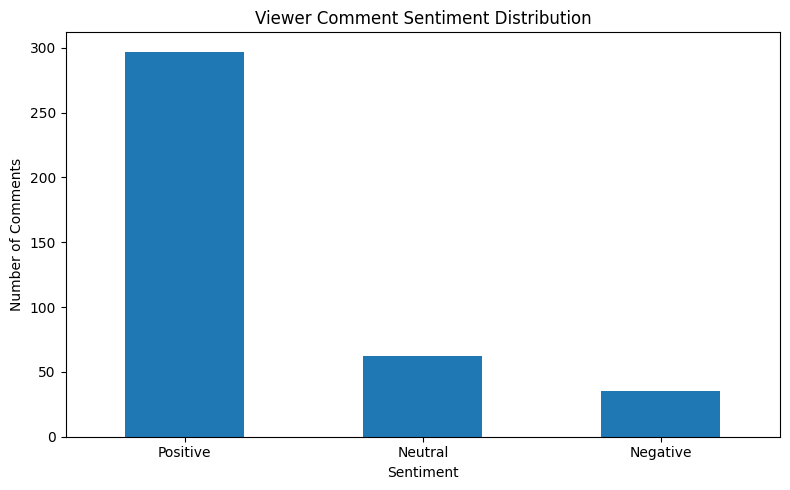

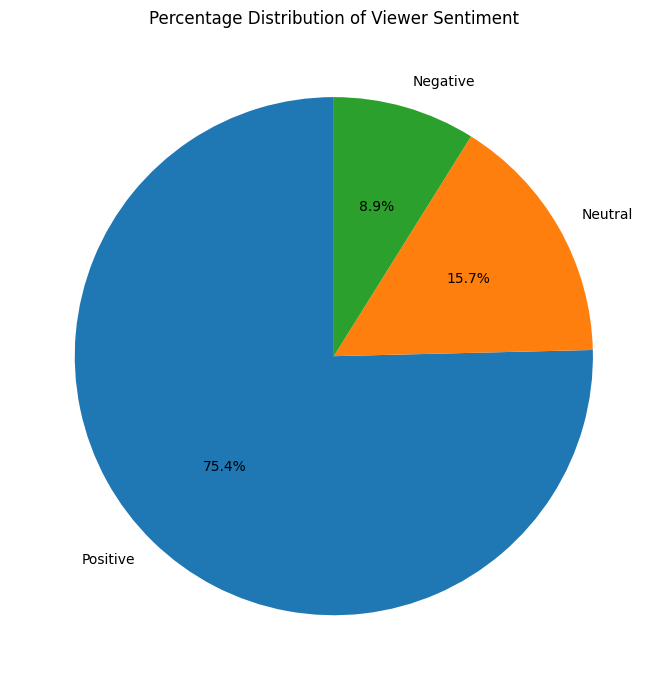

In [ ]:
# STEP 16: Sentiment visualization

import matplotlib.pyplot as plt

if not comments_df.empty and not sentiment_df.empty:

    sentiment_counts = sentiment_df["sentiment"].value_counts()

    plt.figure(figsize=(8, 5))
    sentiment_counts.plot(
        kind="bar",
        title="Viewer Comment Sentiment Distribution"
    )
    plt.xlabel("Sentiment")
    plt.ylabel("Number of Comments")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(7, 7))
    sentiment_counts.plot(
        kind="pie",
        autopct="%1.1f%%",
        startangle=90
    )
    plt.title("Percentage Distribution of Viewer Sentiment")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

else:
    print("No sentiment data available for visualization.")

In [ ]:
# STEP 17: Content gap identification using PySpark

from pyspark.sql.functions import sum as spark_sum, lit

# Count each topic by channel type
topic_comparison = (
    filtered_words
    .groupBy("channel_type", "word")
    .count()
)

# Calculate total words in each channel group
group_totals = (
    topic_comparison
    .groupBy("channel_type")
    .agg(spark_sum("count").alias("total_words"))
)

# Calculate normalized topic frequency
topic_shares = (
    topic_comparison
    .join(group_totals, "channel_type")
    .withColumn(
        "topic_share",
        col("count") / col("total_words")
    )
)

# Separate target and competitor topic shares
target_topics = (
    topic_shares
    .filter(col("channel_type") == "Target")
    .select(
        "word",
        col("topic_share").alias("target_share")
    )
)

competitor_topics = (
    topic_shares
    .filter(col("channel_type") == "Competitor")
    .select(
        "word",
        col("topic_share").alias("competitor_share")
    )
)

# Compare both groups
content_gaps = (
    target_topics
    .join(competitor_topics, "word", "full")
    .fillna(0)
    .withColumn(
        "competitor_gap",
        col("competitor_share") - col("target_share")
    )
    .orderBy(desc("competitor_gap"))
)

print("TOP POTENTIAL CONTENT GAPS")
content_gaps.show(25, truncate=False)

# Save results
gap_path = os.path.join(
    PROJECT_DIR, "dataset/analytics/content_gaps"
)

content_gaps.coalesce(1).write \
    .mode("overwrite") \
    .option("header", True) \
    .csv(gap_path)

print("Content-gap analysis saved at:", gap_path)

TOP POTENTIAL CONTENT GAPS
+---------+------------+---------------------+---------------------+
|word     |target_share|competitor_share     |competitor_gap       |
+---------+------------+---------------------+---------------------+
|python   |0.0         |0.017197074520656257 |0.017197074520656257 |
|computer |0.0         |0.012650721486459775 |0.012650721486459775 |
|java     |0.0         |0.010476378730974501 |0.010476378730974501 |
|explained|0.0         |0.009290373591618897 |0.009290373591618897 |
|gcse     |0.0         |0.009092706068392962 |0.009092706068392962 |
|html     |0.0         |0.008895038545167029 |0.008895038545167029 |
|science  |0.0         |0.008302035975489227 |0.008302035975489227 |
|css      |0.0         |0.007906700929037358 |0.007906700929037358 |
|part     |0.0         |0.0075113658825854916|0.0075113658825854916|
|web      |0.0         |0.006523028266455821 |0.006523028266455821 |
|system   |0.0         |0.006523028266455821 |0.006523028266455821 |
|data  

In [ ]:
# STEP 18: Canopy clustering of video performance

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Prepare numerical features
cluster_df = all_videos_df[
    ["video_id", "channel_name", "channel_type", "title",
     "views", "likes", "comments_count", "engagement_rate"]
].copy()

numeric_features = [
    "views", "likes", "comments_count", "engagement_rate"
]

cluster_df[numeric_features] = (
    cluster_df[numeric_features]
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0)
)

# Log-transform count-based features
cluster_df["views_log"] = np.log1p(cluster_df["views"])
cluster_df["likes_log"] = np.log1p(cluster_df["likes"])
cluster_df["comments_log"] = np.log1p(cluster_df["comments_count"])

features = [
    "views_log", "likes_log", "comments_log", "engagement_rate"
]

scaler = StandardScaler()
X = scaler.fit_transform(cluster_df[features])

# Canopy clustering implementation
def canopy_clustering(data, T1=2.5, T2=1.5):
    remaining = list(range(len(data)))
    centers = []
    canopies = []

    while remaining:
        center_index = remaining[0]
        center = data[center_index]

        centers.append(center)
        canopy_members = []

        for index in remaining:
            distance = np.linalg.norm(data[index] - center)

            if distance < T1:
                canopy_members.append(index)

        canopies.append(canopy_members)

        # Remove points within the tighter threshold
        remaining = [
            index for index in remaining
            if np.linalg.norm(data[index] - center) >= T2
        ]

    return centers, canopies

centers, canopies = canopy_clustering(X, T1=2.5, T2=1.5)

# Assign each video to its nearest canopy center
center_array = np.array(centers)

distances = np.linalg.norm(
    X[:, np.newaxis, :] - center_array[np.newaxis, :, :],
    axis=2
)

cluster_df["canopy_cluster"] = np.argmin(distances, axis=1)

print("CANOPY CLUSTERING COMPLETED")
print("Number of canopies:", len(canopies))
print("Number of videos clustered:", len(cluster_df))

print("\nCluster distribution:")
display(
    cluster_df["canopy_cluster"]
    .value_counts()
    .sort_index()
    .to_frame("video_count")
)

print("\nCluster characteristics:")
display(
    cluster_df.groupby("canopy_cluster")[
        ["views", "likes", "comments_count", "engagement_rate"]
    ].mean().round(2)
)

# Save clustered dataset
canopy_path = os.path.join(
    PROJECT_DIR, "dataset/analytics/canopy_clusters.csv"
)

cluster_df.to_csv(canopy_path, index=False)

print("Canopy results saved at:", canopy_path)

CANOPY CLUSTERING COMPLETED
Number of canopies: 18
Number of videos clustered: 816

Cluster distribution:


,video_count
canopy_cluster,
0,130
1,192
2,34
3,81
4,20
5,95
6,43
7,11
8,1



Cluster characteristics:


,views,likes,comments_count,engagement_rate
canopy_cluster,,,,
0,50221.23,900.62,55.21,2.23
1,5446.49,81.54,4.41,1.67
2,527892.03,11714.15,523.50,2.45
3,1029.44,35.73,2.90,3.83
4,125685.85,5479.70,304.45,4.73
5,183.49,1.25,0.02,0.56
6,166.77,3.81,0.16,2.58
7,1.91,0.00,0.00,0.00
8,15977.00,1626.00,303.00,12.07


Canopy results saved at: /content/drive/MyDrive/YouTube_BigData_CA2/dataset/analytics/canopy_clusters.csv


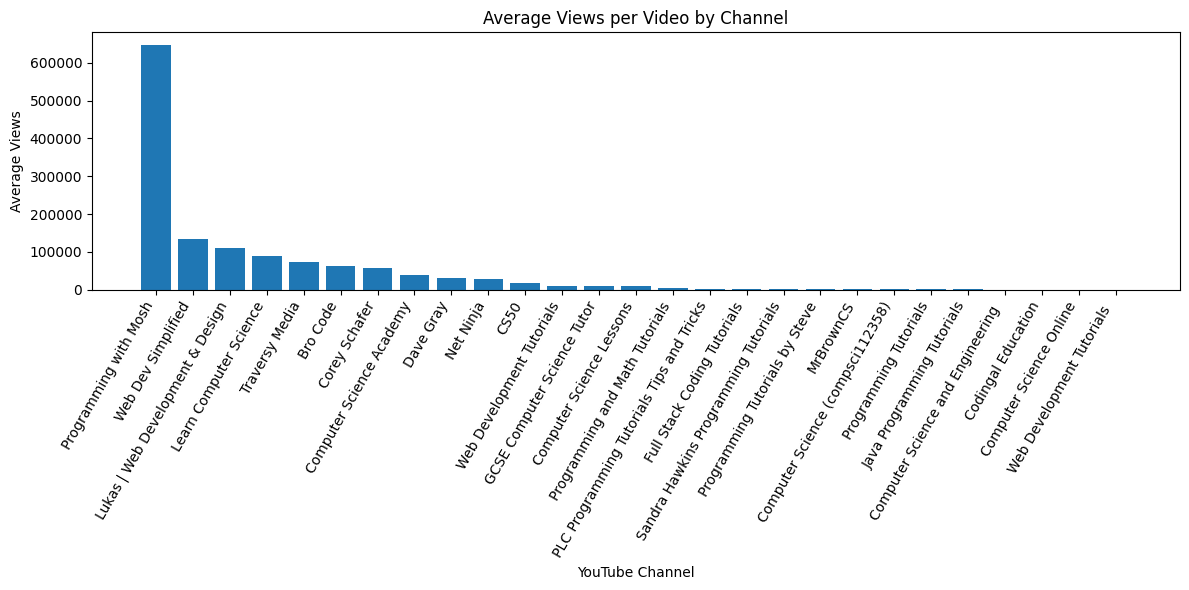

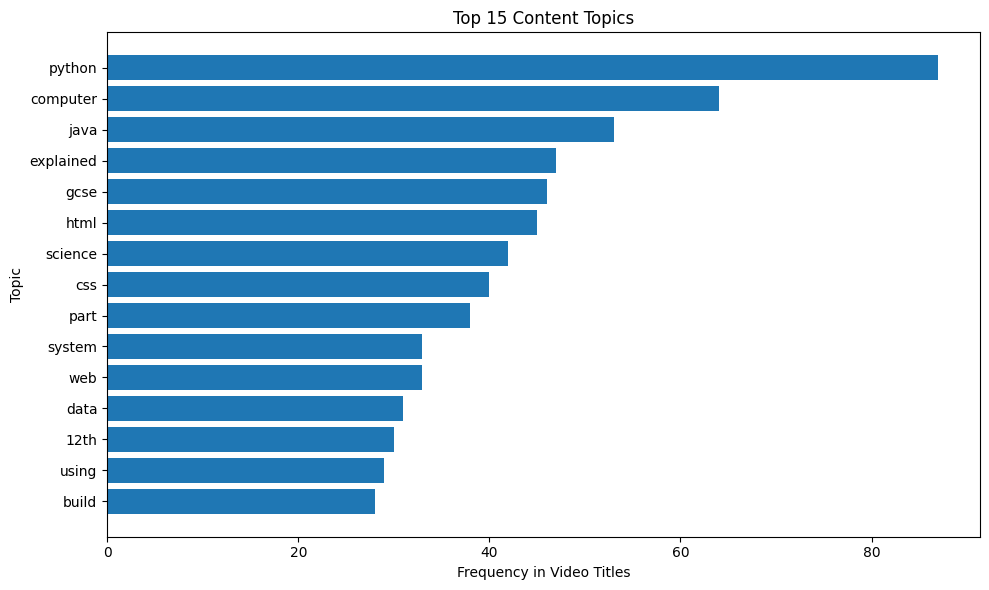

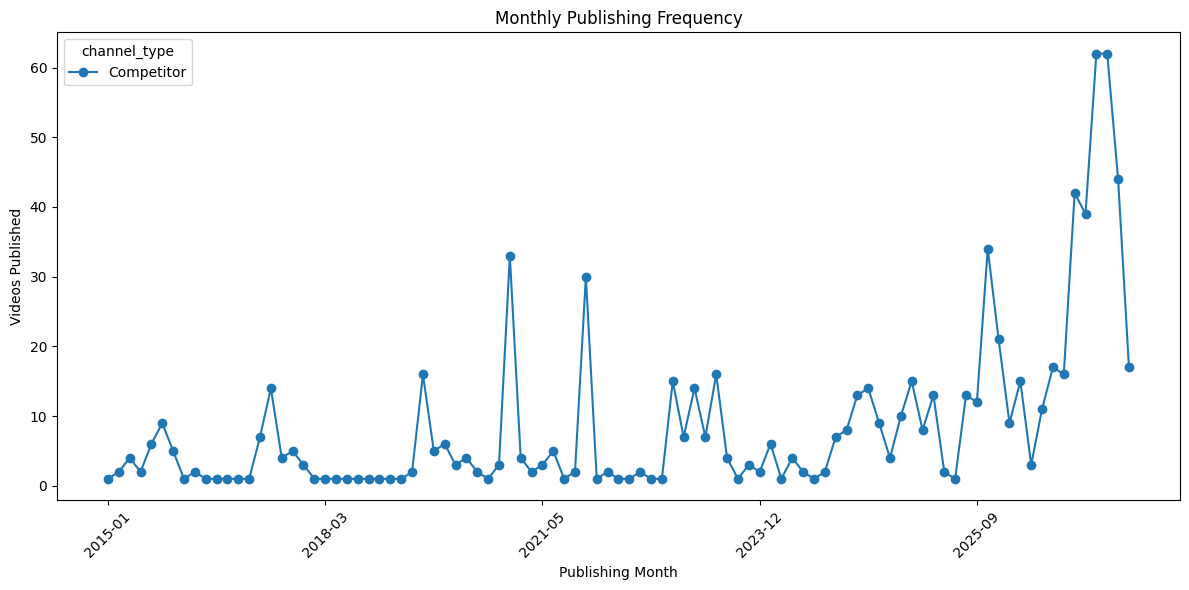

All three charts generated and saved successfully.


In [ ]:
# STEP 19: Competitive analytics visualizations

import matplotlib.pyplot as plt
import pandas as pd
import os

# 1. Average views by channel
performance_pd = channel_performance.toPandas()

plt.figure(figsize=(12, 6))
plt.bar(
    performance_pd["channel_name"],
    performance_pd["average_views"]
)
plt.title("Average Views per Video by Channel")
plt.xlabel("YouTube Channel")
plt.ylabel("Average Views")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.savefig(
    os.path.join(PROJECT_DIR, "outputs/charts/channel_comparison.png")
)
plt.show()

# 2. Most frequent content topics
topics_pd = popular_topics.limit(15).toPandas()

plt.figure(figsize=(10, 6))
plt.barh(topics_pd["word"], topics_pd["frequency"])
plt.title("Top 15 Content Topics")
plt.xlabel("Frequency in Video Titles")
plt.ylabel("Topic")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(
    os.path.join(PROJECT_DIR, "outputs/charts/popular_topics.png")
)
plt.show()

# 3. Monthly publishing frequency
frequency_pd = monthly_frequency.toPandas()

monthly_totals = (
    frequency_pd.groupby(
        ["publish_month", "channel_type"]
    )["videos_published"]
    .sum()
    .unstack(fill_value=0)
)

monthly_totals.plot(
    kind="line",
    marker="o",
    figsize=(12, 6)
)

plt.title("Monthly Publishing Frequency")
plt.xlabel("Publishing Month")
plt.ylabel("Videos Published")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    os.path.join(PROJECT_DIR, "outputs/charts/publishing_frequency.png")
)
plt.show()

print("All three charts generated and saved successfully.")

In [ ]:
# STEP 20: Automated strategy generation

strategies = []

# Strategy 1: Content opportunities
gap_pd = content_gaps.toPandas()

opportunities = (
    gap_pd[gap_pd["competitor_gap"] > 0]
    .sort_values("competitor_gap", ascending=False)
    .head(5)
)

for _, row in opportunities.iterrows():
    strategies.append({
        "strategy_category": "Content Opportunity",
        "recommendation": (
            f"Consider creating more content around '{row['word']}'. "
            "It has a higher relative frequency in competitor video titles."
        ),
        "evidence": __builtins__.round(float(row["competitor_gap"]), 5)
    })

# Strategy 2: Engagement improvement
target_performance = performance_pd[
    performance_pd["channel_type"] == "Target"
]

competitor_performance = performance_pd[
    performance_pd["channel_type"] == "Competitor"
]

if not target_performance.empty and not competitor_performance.empty:

    target_engagement = target_performance[
        "avg_engagement_rate"
    ].mean()

    competitor_engagement = competitor_performance[
        "avg_engagement_rate"
    ].mean()

    if target_engagement < competitor_engagement:
        strategies.append({
            "strategy_category": "Audience Engagement",
            "recommendation": (
                "Explore stronger calls to action, practical exercises "
                "and audience interaction to improve engagement."
            ),
            "evidence": (
                f"Target average: {target_engagement:.3f}%; "
                f"competitor average: {competitor_engagement:.3f}%"
            )
        })
    else:
        strategies.append({
            "strategy_category": "Audience Engagement",
            "recommendation": (
                "Maintain the target channel's engagement performance "
                "and study which video formats generate the most interaction."
            ),
            "evidence": (
                f"Target average: {target_engagement:.3f}%; "
                f"competitor average: {competitor_engagement:.3f}%"
            )
        })

# Strategy 3: Publishing consistency
if not publishing_summary.isEmpty():
    top_publisher = (
        publishing_summary
        .orderBy(desc("avg_monthly_videos"))
        .first()
    )

    strategies.append({
        "strategy_category": "Publishing Strategy",
        "recommendation": (
            f"Review the publishing pattern of {top_publisher['channel_name']} "
            "and use it as a reference when planning a consistent schedule."
        ),
        "evidence": (
            f"Average videos per active month: "
            f"{top_publisher['avg_monthly_videos']}"
        )
    })

strategy_df = pd.DataFrame(strategies)

strategy_path = os.path.join(
    PROJECT_DIR, "outputs/reports/strategy_recommendations.csv"
)

strategy_df.to_csv(strategy_path, index=False)

print("AUTOMATED STRATEGY GENERATION COMPLETED")
display(strategy_df)

print("Saved at:", strategy_path)

AUTOMATED STRATEGY GENERATION COMPLETED


,strategy_category,recommendation,evidence
0,Content Opportunity,Consider creating more content around 'python'...,0.0172
1,Content Opportunity,Consider creating more content around 'compute...,0.01265
2,Content Opportunity,Consider creating more content around 'java'. ...,0.01048
3,Content Opportunity,Consider creating more content around 'explain...,0.00929
4,Content Opportunity,Consider creating more content around 'gcse'. ...,0.00909
5,Publishing Strategy,Review the publishing pattern of Web Developme...,Average videos per active month: 30.0


Saved at: /content/drive/MyDrive/YouTube_BigData_CA2/outputs/reports/strategy_recommendations.csv


In [ ]:
# STEP 21: Create project summary report

summary_records = []

# Fallback or safely fetch video_df length
target_video_count = len(video_df) if 'video_df' in globals() else 0

# Dataset sizes
summary_records.extend([
    {
        "metric": "Target channel videos collected",
        "value": target_video_count
    },
    {
        "metric": "Competitor channels discovered",
        "value": len(competitor_df)
    },
    {
        "metric": "Competitor videos collected",
        "value": len(competitor_video_df)
    },
    {
        "metric": "Viewer comments collected",
        "value": len(comments_df)
    },
    {
        "metric": "Unique videos after cleaning",
        "value": len(all_videos_df)
    },
    {
        "metric": "Canopy clusters generated",
        "value": len(canopies)
    }
])

# Add sentiment statistics when available
if not comments_df.empty and not sentiment_df.empty:
    sentiment_counts = sentiment_df["sentiment"].value_counts()

    for sentiment, count_value in sentiment_counts.items():
        summary_records.append({
            "metric": f"{sentiment} comments",
            "value": int(count_value)
        })

# Add leading content opportunities
for _, row in opportunities.head(5).iterrows():
    summary_records.append({
        "metric": f"Content opportunity: {row['word']}",
        "value": __builtins__.round(float(row["competitor_gap"]), 5)
    })

summary_df = pd.DataFrame(summary_records)

summary_path = os.path.join(
    PROJECT_DIR, "outputs/reports/project_summary.csv"
)

summary_df.to_csv(summary_path, index=False)

print("PROJECT SUMMARY GENERATED")
display(summary_df)

print("Saved at:", summary_path)

PROJECT SUMMARY GENERATED


,metric,value
0,Target channel videos collected,0.00000
1,Competitor channels discovered,29.00000
2,Competitor videos collected,816.00000
3,Viewer comments collected,394.00000
4,Unique videos after cleaning,816.00000
5,Canopy clusters generated,18.00000
6,Positive comments,297.00000
7,Neutral comments,62.00000
8,Negative comments,35.00000
9,Content opportunity: python,0.01720


Saved at: /content/drive/MyDrive/YouTube_BigData_CA2/outputs/reports/project_summary.csv


In [ ]:
# STEP 22: Final project file verification

import os
import pandas as pd

expected_files = [
    "dataset/raw/channel_data.csv",
    "dataset/raw/competitor_channels.csv",
    "dataset/raw/competitor_video_data.csv",
    "dataset/raw/comments.csv",
    "dataset/processed/all_videos_cleaned.csv",
    "dataset/analytics/comment_sentiment.csv",
    "dataset/analytics/canopy_clusters.csv",
    "outputs/charts/channel_comparison.png",
    "outputs/charts/popular_topics.png",
    "outputs/charts/publishing_frequency.png",
    "outputs/reports/strategy_recommendations.csv",
    "outputs/reports/project_summary.csv"
]

verification = []

for relative_path in expected_files:
    full_path = os.path.join(PROJECT_DIR, relative_path)

    verification.append({
        "file": relative_path,
        "status": "AVAILABLE" if os.path.exists(full_path) else "MISSING"
    })

verification_df = pd.DataFrame(verification)

print("FINAL PROJECT FILE VERIFICATION")
display(verification_df)

available = (
    verification_df["status"] == "AVAILABLE"
).sum()

missing = (
    verification_df["status"] == "MISSING"
).sum()

print(f"\nAvailable files: {available}")
print(f"Missing files: {missing}")

if missing == 0:
    print("\nALL EXPECTED PROJECT OUTPUTS ARE AVAILABLE!")
else:
    print("\nSome files are missing. Check the corresponding earlier cells.")

FINAL PROJECT FILE VERIFICATION


,file,status
0,dataset/raw/channel_data.csv,AVAILABLE
1,dataset/raw/competitor_channels.csv,AVAILABLE
2,dataset/raw/competitor_video_data.csv,AVAILABLE
3,dataset/raw/comments.csv,AVAILABLE
4,dataset/processed/all_videos_cleaned.csv,AVAILABLE
5,dataset/analytics/comment_sentiment.csv,AVAILABLE
6,dataset/analytics/canopy_clusters.csv,AVAILABLE
7,outputs/charts/channel_comparison.png,AVAILABLE
8,outputs/charts/popular_topics.png,AVAILABLE
9,outputs/charts/publishing_frequency.png,AVAILABLE



Available files: 12
Missing files: 0

ALL EXPECTED PROJECT OUTPUTS ARE AVAILABLE!


In [ ]:
# STEP 23: Package project datasets for Cloudera

import os
import zipfile

transfer_zip = os.path.join(
    PROJECT_DIR, "YouTube_Cloudera_Transfer.zip"
)

folders_to_include = [
    "dataset/raw",
    "dataset/processed",
    "dataset/analytics",
    "outputs/reports"
]

with zipfile.ZipFile(
    transfer_zip, "w", zipfile.ZIP_DEFLATED
) as zipf:

    for folder in folders_to_include:
        folder_path = os.path.join(PROJECT_DIR, folder)

        if not os.path.exists(folder_path):
            continue

        for root, dirs, files in os.walk(folder_path):
            for filename in files:
                full_path = os.path.join(root, filename)

                # Skip temporary files
                if filename.startswith(".") or filename.endswith(".crc"):
                    continue

                relative_path = os.path.relpath(
                    full_path, PROJECT_DIR
                )

                zipf.write(full_path, relative_path)

print("CLOUDERA TRANSFER PACKAGE CREATED")
print("-----------------------------------")
print("Package:", transfer_zip)
print("Size:", __builtins__.round(os.path.getsize(transfer_zip) / (1024 * 1024), 2), "MB")
print("Exists:", os.path.exists(transfer_zip))

CLOUDERA TRANSFER PACKAGE CREATED
-----------------------------------
Package: /content/drive/MyDrive/YouTube_BigData_CA2/YouTube_Cloudera_Transfer.zip
Size: 0.55 MB
Exists: True


In [ ]:
# STEP 24: Download project package

from google.colab import files

transfer_zip = os.path.join(
    PROJECT_DIR, "YouTube_Cloudera_Transfer.zip"
)

files.download(transfer_zip)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>